# Conditional squeezing: fixed sideband, strategic cancellation tests

The target is the complete **8 dB conditional squeezing unitary** on qubit g/e
× Fock n=0..8, not vacuum squeezing. The fastest currently verified fixed-pump
reference takes **4.81 us at99.0183% coherent process fidelity**. The pump phase
and plateau amplitude stay constant; only its outer5ns ramps change amplitude.
All qubit pi envelopes remain30ns and the peak coupling respects the200ns
minimum swap time.

This 160-pulse reference is a compiled qubit-phase solution. It is not explained
by assigning a low Magnus order to the whole long train. We use short-block
Magnus calculations to propose simpler cancellation mechanisms, then let the
full unitary simulation decide. None of the new tested strategic constructions
has yet beaten the reference at 99%.

The reference optimization varied the 160 physical qubit pi-pulse axes at fixed
sideband strength, amplitude, phase and pulse duration. Its objective was the
same coherent18-column target score, allowing one declared final qubit Z
frame. It used continuation from longer fitted trains and motivated
commutator/phase-cycle starts. The saved solution is a local numerical result;
its literal axes are exported below. SDK packing, filtering and independent
cutoff checks are subsequent acceptance steps, rather than fitted targets.

The ideal qubit drive is assumed calibrated at the chosen steady pump-on
frequency. Unknown power-dependent detuning during turn-on/off is not modeled.
Historical amplitude-modulated and phase-modulated faster gates are archived;
they are not fixed-pump recommendations.

In [1]:
# Locate code/ when this notebook is opened from notebooks/ or archive/.
from pathlib import Path as _Path
import sys as _sys
_project=next(p for p in [_Path.cwd(),*_Path.cwd().parents]
              if (p/'code/project_paths.py').is_file())
if str(_project/'code') not in _sys.path:
    _sys.path.insert(0,str(_project/'code'))
from project_paths import ROOT as PROJECT_ROOT, CODE, NOTEBOOKS


import os
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from project_paths import ROOT
import cd_trains as cd
import hardware_check as hw
from notebook_figures import read,certificate,drives,finish,waveform_figure,individual_overlaps,DATA

ref=certificate('squeeze_constant_reference')
display(pd.DataFrame([{k:ref[k] for k in ['command_us','fidelity','worst_basis_fidelity','peak_swap_ns','qubit_frame_Rz','levels']}]))
print('Independent full-gate check:',ref['columns'],'input columns;',ref['complex_amplitudes'],
      'amplitudes;max difference',ref['independent_max_difference'])


,command_us,fidelity,worst_basis_fidelity,peak_swap_ns,qubit_frame_Rz,levels
0,4.81,0.990183,0.959283,351.570348,-3.331688,320


Independent full-gate check: 18 input columns; 11520 amplitudes;max difference 3.1207747653061754e-15


## Pulse spacing at fixed8dB target and fixed4.81 us duration

This is a controlled Trotter comparison: repeat the same proper eight-pulse
cycle, with operator axes **Y,X,Y,X,−Y,−X,−Y,−X**, while changing its idle time
and repeat count. Physical DAC angles are270,0,270,0,90,180,90,180 degrees.
Every pi envelope is30ns, and every point lasts exactly4.810 us including
outer ramps. The spacing is center-to-center, not an adjustable pi width.

For each spacing, normalize one constant JC strength so the wanted second
Magnus coefficient of the **packed/RFDC waveform** is $r/2$, with
$r=8\ln(10)/20$. Pulse axes and coupling are not optimized for fidelity.
As in the reference, one declared final qubit Z frame is calibrated and
included, with the same angle applied to all 18 inputs. The wanted quadratic
generator therefore stays8dB to the DAC resolution; every fidelity still compares with
the same exact8dB target on all 18 inputs.

The dashed8dB line is the wanted generator strength. The solid vacuum curve
shows implementation error in an observable; it is not used to choose or
rename the target. The black star is the separate optimized160-axis reference,
at the same duration and30ns spacing. Its phases differ from the repeated
eight-pulse Trotter word; do not join it into that word's convergence curve.

Reducing spacing from300ns to37.5 ns improves this repeated-cycle fidelity
from30.64% to87.74%; the30ns point is86.29%. This last turnover is possible
because the pi duration is fixed: keeping8dB in the same time requires
stronger JC as spacing decreases, increasing JC evolution during each pulse.
Thus this is not a limit in which every control timescale shrinks together.
It does not meet 99% at any spacing tested; the optimized reference does.

In the instantaneous-pulse commutator limit,

$$r\propto g^2 T\Delta,\qquad g\propto\Delta^{-1/2}
\quad\text{at fixed }r,T.$$

Here $\tau_\pi=30\,\mathrm{ns}$ is fixed, so $g\tau_\pi$ increases rather than
vanishing. The exact normalization uses the played-waveform coefficient,
not this approximate rate formula.

Both target and output cutoffs are independently converged. The
[full data](../runs/pulse_spacing/summary.json) and
[dense-cycle timing table](../runs/pulse_spacing/squeeze_T4810_N160_pulses.csv)
give every physical wait and axis.

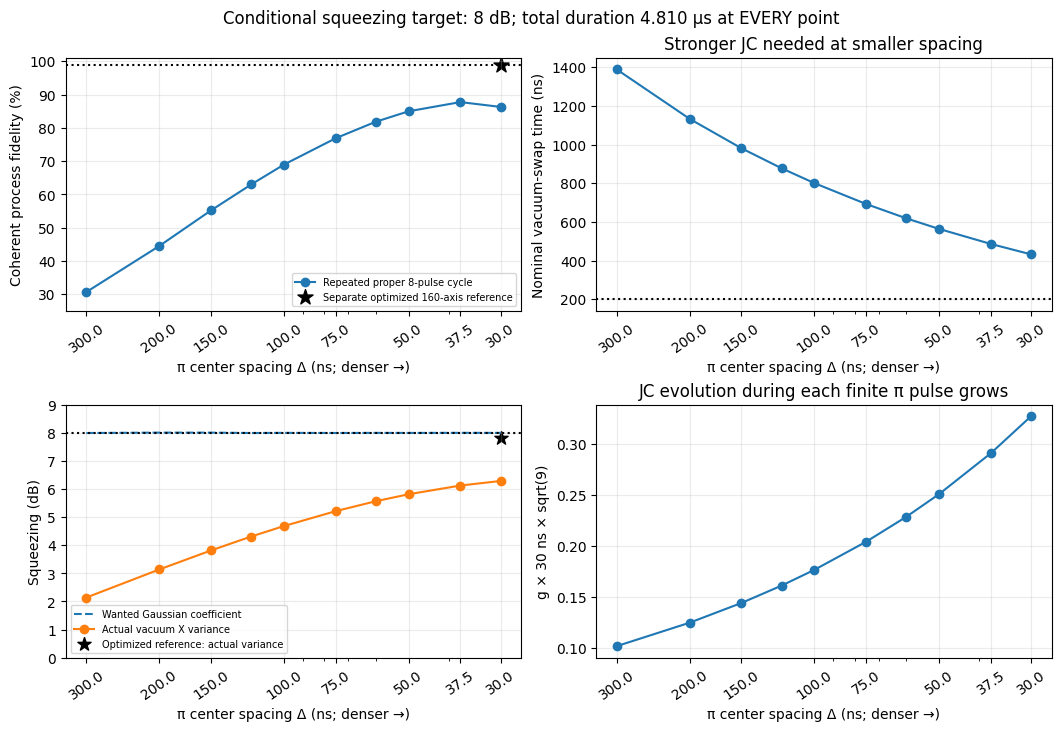

,cells,spacing_ns,gap_ns,nominal_swap_ns,vacuum_target_axis_squeezing_dB,qubit_frame_Rz,levels,process_fidelity_percent,nominal_gate_dB
8,16,300.0,270.0,1388.615047,2.139053,0.001106,320,30.635508,7.996603
9,24,200.0,170.0,1132.956269,3.138580,0.002429,320,44.480429,8.010726
10,32,150.0,120.0,981.041412,3.815875,0.003589,320,55.178790,8.009626
11,40,120.0,90.0,877.531738,4.311740,0.004860,320,62.967107,7.996719
12,48,100.0,70.0,800.735643,4.683754,0.006272,320,68.951829,8.001458
13,64,75.0,45.0,692.712702,5.214426,0.009440,320,76.869389,7.997558
14,80,60.0,30.0,618.723626,5.568111,0.013412,320,81.843298,8.000898
15,96,50.0,20.0,563.856653,5.816410,0.018523,320,84.977557,7.999474
16,128,37.5,7.5,486.195602,6.126261,0.033707,320,87.744655,8.003050
17,160,30.0,0.0,432.418041,6.288426,0.056188,320,86.290651,8.000660


SQUEEZING SPACING CHECK:10 points;180 input columns; 115200 independent complex amplitudes;all targets8dB;all durations4.810us


In [2]:

from pulse_spacing_figures import squeeze_figure,load as spacing_data
spacing_report,spacing_rows=spacing_data()
table=squeeze_figure()
display(table.assign(process_fidelity_percent=lambda r:100*r.fidelity,
    nominal_gate_dB=lambda r:40*r.wanted_coefficient_actual/np.log(10)).drop(columns=['fidelity','wanted_coefficient_actual']))
sq_spacing=spacing_rows[spacing_rows.gate=='squeeze']
assert len(sq_spacing)==10 and max(abs(sq_spacing.command_us-4.810))<1e-12
print('SQUEEZING SPACING CHECK:10 points;180 input columns;',int(sq_spacing.independent_amplitudes.sum()),
      'independent complex amplitudes;all targets8dB;all durations4.810us')


## 1. Why the full input subspace matters

The exact target is

$$S_z(r)=\exp[\tfrac r2\sigma_z(a^2-a^{\dagger2})],\qquad r=8\ln(10)/20.$$

The coherent process fidelity includes all 18 columns and their relative
phases. The state fidelities below show where error grows with photon number.
Output cutoff convergence is required separately from preparing inputs only
up to8 photons; squeezing can populate much higher Fock states.

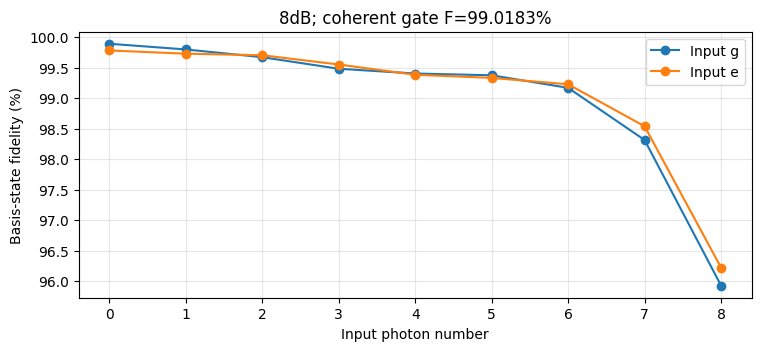

In [3]:

overlaps=individual_overlaps('squeeze_constant_reference')
assert abs(abs(overlaps.mean())**2-ref['fidelity'])<1e-13
fig,ax=plt.subplots(figsize=(7.5,3.4),constrained_layout=True)
for offset,label in [(0,'Input g'),(9,'Input e')]:ax.plot(np.arange(9),100*abs(overlaps[offset:offset+9])**2,'o-',label=label)
ax.set(xlabel='Input photon number',ylabel='Basis-state fidelity (%)',title=f"8dB; coherent gate F={100*ref['fidelity']:.4f}%")
ax.grid(alpha=.3);ax.legend();finish('squeeze_all_input_diagnostics')


## 2. Work out what a symmetry removes before simulating the gate

The short-block search enumerated 65,536 eight-pulse X/Y/−X/−Y words.
680 close the qubit operation and cancel the first-order JC average. Only 16
produce the desired pure second-order squeezing term. Simply cycling qubit
phases removes only part of their cubic error; the rest survives.

An optional sign-cycle branch uses constant-radius sideband phase arcs:
$I=A\cos\psi(t)$ and $Q=A\sin\psi(t)$, changing phase over10ns while the
qubit envelope is zero. This preserves the programmed magnitude. Straight
Cartesian I/Q interpolation would change it and is not used.

Those phase arcs add a conditional-number term at second order. Pairing
opposite chiralities cancels that term, as the calculation below shows. Yet
the full fast gates still fail 99%; cancellation of one coefficient does not
establish gate fidelity. This optional branch is therefore not recommended
over the simpler fixed-pump reference. It also has small filtered magnitude
ripple, which cannot be called perfectly constant at the device.

Arc/chirality terms (complete saved calculations):


[{'block_index': 0,
  'word': [1, 0, 1, 0, 3, 2, 3, 2],
  'repeats': 2,
  'chirality_cycle': False,
  'first_norm': 1.5696879196070206e-16,
  'second_squeeze': 0.013959617944027398,
  'second_qubit_Z': 8.186490479518913e-05,
  'second_chi': 0.00016372980959035522,
  'second_unwanted_norm': 2.0757339381229686e-15,
  'cubic_norm': 0.001398925989873058,
  'quartic_norm': 0.00038774922565464054},
 {'block_index': 0,
  'word': [1, 0, 1, 0, 3, 2, 3, 2],
  'repeats': 2,
  'chirality_cycle': True,
  'first_norm': 8.631850606171061e-17,
  'second_squeeze': 0.013959617944027398,
  'second_qubit_Z': 2.3600060788418893e-05,
  'second_chi': 4.720012157681847e-05,
  'second_unwanted_norm': 2.0799006194792493e-15,
  'cubic_norm': 0.0006548349551703133,
  'quartic_norm': 0.00035914062896686756},
 {'block_index': 1,
  'word': [3, 0, 3, 0, 1, 2, 1, 2],
  'repeats': 2,
  'chirality_cycle': False,
  'first_norm': 1.4002256192134115e-16,
  'second_squeeze': 0.013959617944027398,
  'second_qubit_Z': 8.18649

[{'block_index': 0,
  'word': [1, 0, 1, 0, 3, 2, 3, 2],
  'repeats': 2,
  'chirality_cycle': False,
  'first_norm': 1.5910897742915334e-16,
  'second_squeeze': 0.013959617944027398,
  'second_qubit_Z': 8.184111162990792e-05,
  'second_chi': 0.00016368222325979383,
  'second_unwanted_norm': 2.0913187595754817e-15,
  'cubic_norm': 0.001278847523838918,
  'quartic_norm': 0.0003861965130961885},
 {'block_index': 0,
  'word': [1, 0, 1, 0, 3, 2, 3, 2],
  'repeats': 2,
  'chirality_cycle': True,
  'first_norm': 6.56109848978419e-17,
  'second_squeeze': 0.013959617944027398,
  'second_qubit_Z': 6.525000087439144e-18,
  'second_chi': -3.5057640426080686e-18,
  'second_unwanted_norm': 2.0954699308989063e-15,
  'cubic_norm': 0.00032754077977682137,
  'quartic_norm': 0.00035753072747722484},
 {'block_index': 1,
  'word': [3, 0, 3, 0, 1, 2, 1, 2],
  'repeats': 2,
  'chirality_cycle': False,
  'first_norm': 1.4073394363361225e-16,
  'second_squeeze': 0.013959617944027398,
  'second_qubit_Z': 8.18411

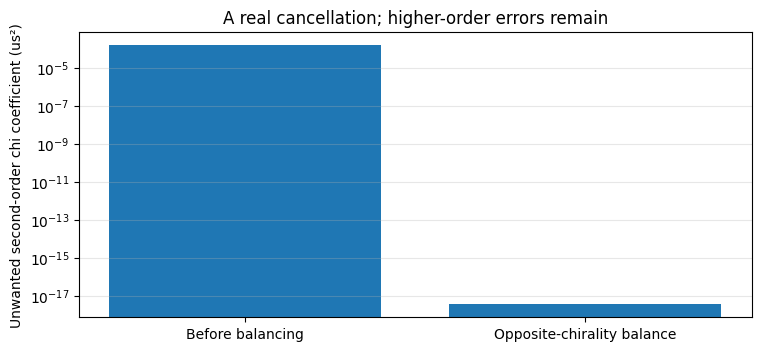

In [4]:

before=read('runs/strategic_squeezing/chirality_magnus.json')
after=read('runs/strategic_squeezing/balanced_magnus.json')
print('Arc/chirality terms (complete saved calculations):');display(before);display(after)
# Compare the same two-repeat supercycle before/after chirality balancing.
chi_before=abs(next(r['second_chi'] for r in after if r['block_index']==0 and not r['chirality_cycle']))
chi_after=abs(next(r['second_chi'] for r in after if r['block_index']==0 and r['chirality_cycle']))
fig,ax=plt.subplots(figsize=(7.5,3.4),constrained_layout=True)
ax.bar(['Before balancing','Opposite-chirality balance'],[chi_before,chi_after])
ax.set(yscale='log',ylabel='Unwanted second-order chi coefficient (us²)',title='A real cancellation; higher-order errors remain')
ax.grid(axis='y',alpha=.3);finish('squeeze_arc_chi_cancellation')


## 3. The surviving error changes with photon number

In the tested 16 proper positive eight-pulse blocks, a quartic term contains

$$E_4\propto\sigma_z(a^{\dagger3}a-a^\dagger a^3).$$

Its upward two-photon matrix element is n times that of the intended
$\sigma_z(a^{\dagger2}-a^2)$ generator. A single coupling calibration can
adjust the mean squeeze strength but cannot remove that n dependence.
All16 blocks have the same sign for this coefficient, so their positive
mixtures and tested target-preserving sign/Pauli cycles cannot cancel it.
This obstruction is limited to that family, not a proof against arbitrary
fractional-angle or timing designs.

The plot compares generator matrix-element shapes only. It is not a gate
infidelity curve. At working coupling, all higher orders must be tested by
full quantum propagation.

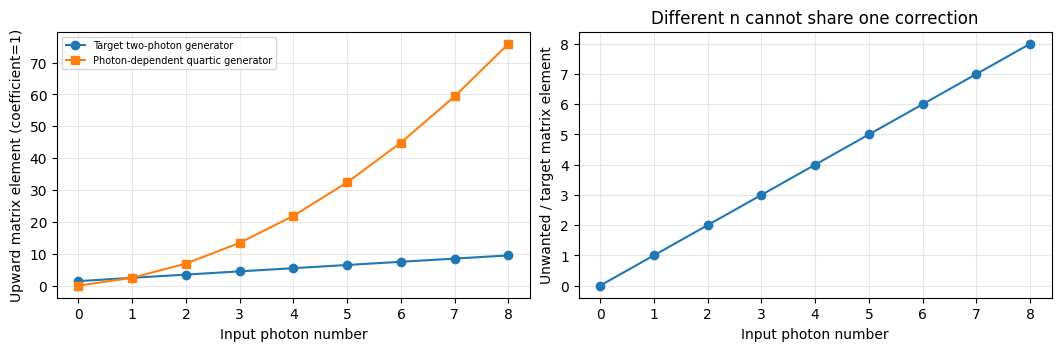

Operator-fit residual: 5.680477470484239e-19


In [5]:

n=np.arange(9);desired=np.sqrt((n+1)*(n+2));unwanted=n*desired
fig,axes=plt.subplots(1,2,figsize=(10.5,3.4),constrained_layout=True)
axes[0].plot(n,desired,'o-',label='Target two-photon generator')
axes[0].plot(n,unwanted,'s-',label='Photon-dependent quartic generator')
axes[0].set(xlabel='Input photon number',ylabel='Upward matrix element (coefficient=1)');axes[0].legend(fontsize=7)
axes[1].plot(n,n,'o-');axes[1].set(xlabel='Input photon number',ylabel='Unwanted / target matrix element',title='Different n cannot share one correction')
for ax in axes:ax.grid(alpha=.3)
finish('squeeze_photon_dependent_error')
print('Operator-fit residual:',read('runs/strategic_squeezing/quartic_operators.json')['residual'])


## 4. Literal fixed-pump reference

The sideband has a constant plateau, nominal swap353.95 ns and phase0degrees,
with outer5ns amplitude ramps. The [full160-pulse table](../runs/research_verified/squeeze_constant_reference_pulses.csv)
lists every physical qubit axis. Each pulse is30ns and a full pi rotation.
Apply the single final qubit Rz printed below after the complete train; this
tracked frame is included in the coherent gate fidelity.

The qubit plot zooms into the first300ns for legibility. The sideband plot
shows the entire4.81 us gate and its constant magnitude. All pulses are present
in the [exact SDK words](../runs/research_verified/squeeze_constant_reference_words.npz).
This is the previously verified numerical reference; its 160 phase parameters
are not presented as a simple higher-order product formula.

,pulse,start_ns,duration_ns,rotation_pi_units,qubit_DAC_deg,reversed_envelope
0,1,5.0,30.0,1.0,84.704412,False
1,2,35.0,30.0,1.0,359.482548,False
2,3,65.0,30.0,1.0,261.012901,False
3,4,95.0,30.0,1.0,21.208767,False
4,5,125.0,30.0,1.0,270.459429,False
5,6,155.0,30.0,1.0,187.773732,False
6,7,185.0,30.0,1.0,93.385052,False
7,8,215.0,30.0,1.0,206.247067,False
8,9,245.0,30.0,1.0,97.034246,False
9,10,275.0,30.0,1.0,357.959045,False


All160phases are in the linked CSV. Final qubit Rz(rad): -3.331687648435443


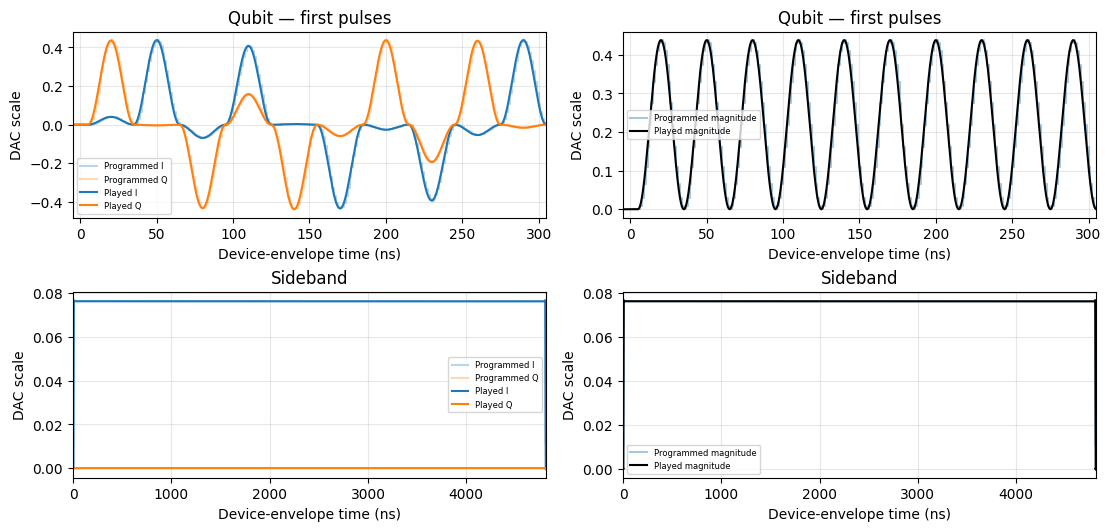

In [6]:

pulses=pd.read_csv(DATA/'squeeze_constant_reference_pulses.csv')
assert len(pulses)==160 and all(pulses.duration_ns==30)
display(pulses.head(12))
print('All160phases are in the linked CSV. Final qubit Rz(rad):',ref['qubit_frame_Rz'])
waveform_figure('squeeze_constant_reference',qubit_zoom_ns=300);finish('squeeze_constant_pump_IQ')


## 5. Fresh boundary-input replay and the decision from the experiments

The full reference certificate independently compares all 18 columns at a
converged output cutoff. This cell additionally replays g8/e8 at384 levels
and compares complex amplitudes against that certificate. No leakage is
discarded and no target is fitted to the achieved state.

The strategic tests produced useful falsifications: correct first/second
Magnus terms do not guarantee accuracy at finite coupling; bridge pulses and
phase arcs contribute their own terms; and a phase symmetry cannot cancel an
error it preserves. A slower, fully checked phase-cycle construction reaches
99.19% only at15.695 us, so it loses the speed comparison. Composite pi/N
qubit sandwiches cancel their added second-order chi when paired, but the
completed faster tests remain below 99%.

The final proposed alternative was a primitive ending in qubit Z, so that
repeating it could cancel qubit-X/Y cubic errors without extra bridge pulses.
A search over all eight- and ten-pulse words made of ±X/±Y pi and pi/2
envelopes found no Z-ending primitive with zero first JC average. Exact
nearest-neighbor matching tests the 855,296 and 50,039,808 relevant endpoint
pairs without simulating a billion full gates. The first-moment calculation
was separately checked against 2,048 oscillator/qubit Cauchy coefficients at
each length. Thus this discrete family fails before any fidelity optimization;
other rotation fractions and timings remain outside that result. Full counts
are saved in [the open-Z search](../runs/open_z_squeezing/length10.json).

Research decisions and comparisons are recorded in [WORK_STATUS](../WORK_STATUS.md)
and the [independent review](../runs/independent_review/REVIEW.md). The current
recommendation stays4.81 us until a shorter gate passes the same full metric.

FRESH SQUEEZE CHECK:2boundaryinputs; 1536 amplitudes;maxdifference 1.531987721386466e-15


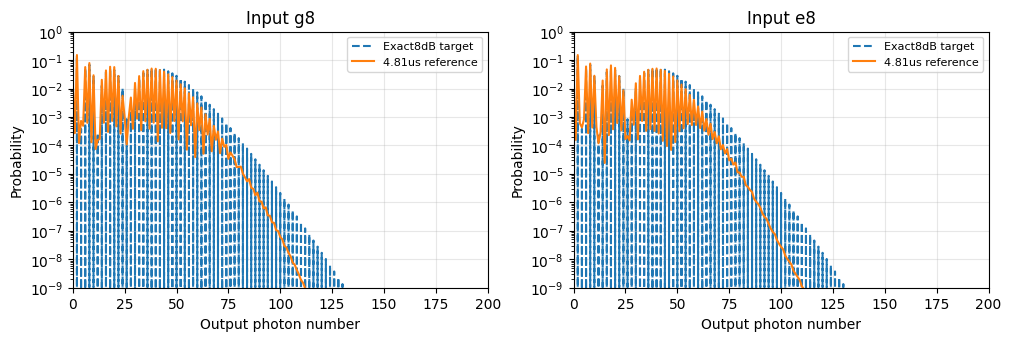

In [7]:

q,s,qf,sf,words=drives('squeeze_constant_reference')
space=cd.Space(384,9);initial=np.eye(768,dtype=complex)[:,[16,17]]
V=hw.propagate(qf,sf,initial,cd.DT/8,order=16)
V*=np.exp(-1j*ref['qubit_frame_Rz']*space.z/2)[:,None]
T=cd.target_columns(space,'squeeze',cd.R_8DB)[:,[8,17]]
saved=np.load(DATA/'squeeze_constant_reference_columns.npz')['output'][:,[8,17]]
pad=np.zeros_like(V);pad[:len(saved)]=saved
error=float(np.max(abs(V-pad)));assert V.shape==(768,2) and error<1e-10
print('FRESH SQUEEZE CHECK:2boundaryinputs;',V.size,'amplitudes;maxdifference',error)
fig,axes=plt.subplots(1,2,figsize=(10,3.3),constrained_layout=True)
for j,ax in enumerate(axes):
    exact=(abs(T[:,j])**2).reshape(-1,2).sum(axis=1)
    actual=(abs(V[:,j])**2).reshape(-1,2).sum(axis=1)
    ax.semilogy(exact,'--',label='Exact8dB target');ax.semilogy(actual,label='4.81us reference')
    ax.set(title=['Input g8','Input e8'][j],xlabel='Output photon number',ylabel='Probability',xlim=(0,200),ylim=(1e-9,1))
    ax.grid(alpha=.3);ax.legend(fontsize=8)
finish('squeeze_boundary_input_replay')
